In [1]:
from lights.load_data import *
from lights.constants import mB, mK, mKs
from lights.signal_rates import Nrec_BelleII, s_SM_BelleII, Nrec_BaBar, s_SM_BaBar

import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from joblib import Parallel, delayed

DATA_DIR = Path(os.getcwd()).resolve().parents[0] / "data" / "BtoKEmiss"
SAVE_DIR = Path(os.getcwd()).resolve().parents[0] / "plots" / "mass_fits"

# Use LaTeX (Computer Modern) if installed; otherwise fall back to mathtext's CM fonts.
# /Library/TeX/texbin is the MacTeX location, which GUI apps may not have on PATH.
if os.path.isdir("/Library/TeX/texbin"):
    os.environ["PATH"] += os.pathsep + "/Library/TeX/texbin"
plt.rcParams.update({
    "font.size": 20,
    "font.family": "serif",
    "font.serif": ["Computer Modern"],
    "mathtext.fontset": "cm",
    "text.usetex": shutil.which("latex") is not None,
})

In [2]:
from lights.branching_fractions import cdict
from lights.likelihoods import logLL_BelleII, min_logLL

mu_val, mu_err, m_BelleII, mu_min = min_logLL(logLL_BelleII, Nrec_BelleII)

In [3]:
import multiprocessing as mp
from functools import partial
import numpy as np
from tqdm import tqdm

# Define at the top level (not inside another function) so workers can find it
def fit_one(mX, logLL, Nrec, Nbins, CNP_1, CNP_2, LAMBDA):
    return min_logLL(logLL, Nrec, Nbins, mX, CNP_1, CNP_2, LAMBDA, NP=1)[3]

# Two-body scenarios

In [4]:
mX_vals = np.append(1e-10, np.linspace(1e-2, 4.0, 1000))

In [5]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CSL_s']] = 1e-8
CNP_1[cdict['CSR_s']] = 1e-8
LAMBDA = 1

LL_vals_gS = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:07<00:00, 129.71it/s]


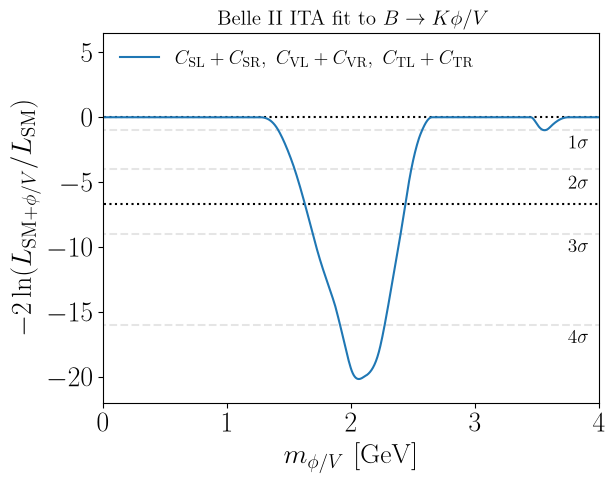

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mX_vals = np.append(1e-10, np.linspace(1e-2, 4.0, 1000))

axes.plot([-1, 4], [-1, -1], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 4], [-4, -4], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 4], [-9, -9], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 4], [-16, -16], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 4], [-25, -25], ls = '--', color='k',alpha = 0.1);

axes.plot([-1, 4], [0, 0], ls = ':', color='k');
axes.plot([-1, 4], [mu_min, mu_min], ls = ':', color='k');
tot1, = axes.plot(mX_vals, LL_vals_gS);

axes.set_xlim(0,4)
axes.set_ylim(-22,6.5)
axes.set_xlabel(r'$m_{\phi/V} \,\, [\mathrm{GeV}]$');
axes.set_ylabel(r'$-2\ln(L_{\mathrm{SM} + \phi/V}/L_\mathrm{SM})$');

# axes.yaxis.set_label_coords(-0.12,0.5)

axes.text(3.75,-2.4, r'$1\sigma$', fontsize=14)
axes.text(3.75,-5.5, r'$2\sigma$', fontsize=14)
axes.text(3.75,-10.4, r'$3\sigma$', fontsize=14)
axes.text(3.75,-17.4, r'$4\sigma$', fontsize=14)

axes.legend([tot1], [
    r'$C_{\rm SL} + C_{\rm SR},~C_{\rm VL} + C_{\rm VR},~C_{\rm TL} + C_{\rm TR}$', 
    ], loc='upper left',fontsize=14,frameon=False)

plt.title(r'Belle~II ITA fit to $B\to K \phi/V$', fontsize = 15);

fig.set_size_inches(6.4, 4.8)
plt.savefig(SAVE_DIR / "2body_mass.pdf", bbox_inches='tight')

# Three-body scenarios

In [7]:
mX_vals = np.append(1e-10, np.linspace(1e-2, 1.5, 1000))

In [8]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CSL_ss']] = 1e-3
CNP_1[cdict['CSR_ss']] = 1e-3
LAMBDA = 1e4

LL_vals_gSS = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:04<00:00, 227.04it/s]


In [9]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CVL_ss']] = 1.0
CNP_1[cdict['CVR_ss']] = 1.0
LAMBDA = 1e4

LL_vals_gVV = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:04<00:00, 220.74it/s]


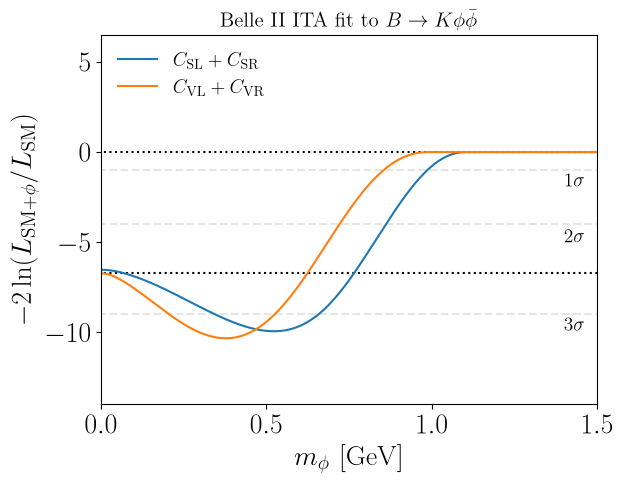

In [10]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mX_vals = np.append(1e-10, np.linspace(1e-2, 1.5, 1000))

axes.plot([-1, 3], [-1, -1], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-4, -4], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-9, -9], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-16, -16], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-25, -25], ls = '--', color='k',alpha = 0.1);

axes.plot([-1, 3], [0, 0], ls = ':', color='k');
axes.plot([-1, 3], [mu_min, mu_min], ls = ':', color='k');
tot1, = axes.plot(mX_vals, LL_vals_gSS);
tot2, = axes.plot(mX_vals, LL_vals_gVV);

axes.set_xlim(0,1.5)
axes.set_ylim(-14,6.5)
axes.set_xlabel(r'$m_\phi \,\, [\mathrm{GeV}]$');
axes.set_ylabel(r'$-2\ln(L_{\mathrm{SM} + \phi}/L_\mathrm{SM})$');

# axes.yaxis.set_label_coords(-0.12,0.5)

axes.text(1.4,-1.9, r'$1\sigma$', fontsize=14)
axes.text(1.4,-5.0, r'$2\sigma$', fontsize=14)
axes.text(1.4,-9.9, r'$3\sigma$', fontsize=14)

axes.legend([tot1,tot2], [
    r'$C_{\rm SL} + C_{\rm SR}$', 
    r'$C_{\rm VL} + C_{\rm VR}$'
    ], loc='upper left',fontsize=14,frameon=False)

plt.title(r'Belle~II ITA fit to $B\to K \phi \bar{\phi}$', fontsize = 15);

fig.set_size_inches(6.4, 4.8)
plt.savefig(SAVE_DIR / "3body_scalar_mass.pdf", bbox_inches='tight')

In [11]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CVL_ff']] = 1.0
CNP_1[cdict['CVR_ff']] = 1.0
LAMBDA = 1e4

LL_vals_fVV = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:04<00:00, 217.14it/s]


In [12]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CVLp_ff']] = 1.0
CNP_1[cdict['CVRp_ff']] = 1.0
LAMBDA = 1e4

LL_vals_fVA = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:04<00:00, 208.36it/s]


In [13]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CSL_ff']] = 1.0
CNP_1[cdict['CSR_ff']] = 1.0
LAMBDA = 1e4

LL_vals_fSS = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 197.77it/s]


In [14]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CSLp_ff']] = 1.0
CNP_1[cdict['CSRp_ff']] = 1.0
LAMBDA = 1e4

LL_vals_fSP = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 186.43it/s]


In [15]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTL_ff']] = 1.0
CNP_1[cdict['CTR_ff']] = 1.0
LAMBDA = 1e4

LL_vals_fTT = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 185.58it/s]


In [16]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTL_ff']] = 1.0
CNP_1[cdict['CTR_ff']] = -1.0
LAMBDA = 1e4

LL_vals_fTtT = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 186.32it/s]


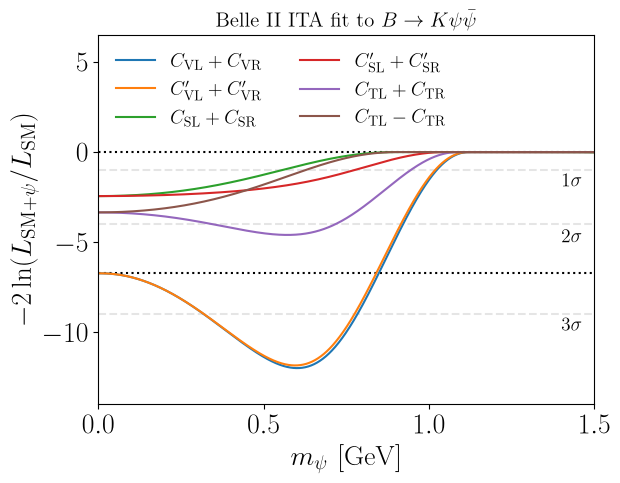

In [17]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mX_vals = np.append(1e-10, np.linspace(1e-2, 1.5, 1000))

axes.plot([-1, 3], [-1, -1], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-4, -4], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-9, -9], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-16, -16], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-25, -25], ls = '--', color='k',alpha = 0.1);

axes.plot([-1, 3], [0, 0], ls = ':', color='k');
axes.plot([-1, 3], [mu_min, mu_min], ls = ':', color='k');
tot1, = axes.plot(mX_vals, LL_vals_fVV);
tot2, = axes.plot(mX_vals, LL_vals_fVA);
tot3, = axes.plot(mX_vals, LL_vals_fSS);
tot4, = axes.plot(mX_vals, LL_vals_fSP);
tot5, = axes.plot(mX_vals, LL_vals_fTT);
tot6, = axes.plot(mX_vals, LL_vals_fTtT);

axes.set_xlim(0,1.5)
axes.set_ylim(-14,6.5)
axes.set_xlabel(r'$m_\psi \,\, [\mathrm{GeV}]$');
axes.set_ylabel(r'$-2\ln(L_{\mathrm{SM} + \psi}/L_\mathrm{SM})$');

axes.yaxis.set_label_coords(-0.12,0.5)

axes.text(1.4,-1.9, r'$1\sigma$', fontsize=14)
axes.text(1.4,-5.0, r'$2\sigma$', fontsize=14)
axes.text(1.4,-9.9, r'$3\sigma$', fontsize=14)

axes.legend([tot1,tot2,tot3,tot4,tot5,tot6], [
    r'$C_{\rm VL} + C_{\rm VR}$', 
    r'$C_{\rm VL}^\prime + C_{\rm VR}^\prime$',
    r'$C_{\rm SL} + C_{\rm SR}$', 
    r'$C_{\rm SL}^\prime + C_{\rm SR}^\prime$',
    r'$C_{\rm TL} + C_{\rm TR}$',
    r'$C_{\rm TL} - C_{\rm TR}$', 
    ], loc='upper left',fontsize=14,frameon=False, ncol=2)

plt.title(r'Belle~II ITA fit to $B\to K \psi \bar{\psi}$', fontsize = 15);

fig.set_size_inches(6.4, 4.8)
plt.savefig(SAVE_DIR / "3body_fermion_mass.pdf", bbox_inches='tight')

In [18]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CSL_vv']] = 1.
CNP_1[cdict['CSR_vv']] = 1.
LAMBDA = 3e2

LL_vals_hS = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 197.26it/s]


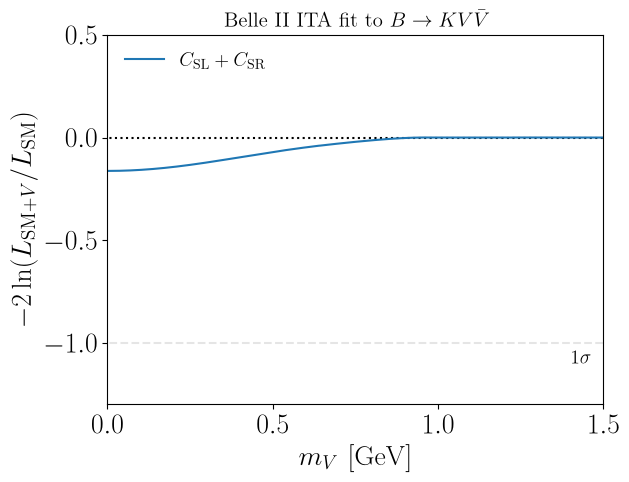

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mX_vals = np.append(1e-10, np.linspace(1e-2, 1.5, 1000))

axes.plot([-1, 3], [-1, -1], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-4, -4], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-9, -9], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-16, -16], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-25, -25], ls = '--', color='k',alpha = 0.1);

axes.plot([-1, 3], [0, 0], ls = ':', color='k');
axes.plot([-1, 3], [mu_min, mu_min], ls = ':', color='k');
tot1, = axes.plot(mX_vals, LL_vals_hS);

axes.set_xlim(0,1.5)
axes.set_ylim(-1.3,0.5)
axes.set_xlabel(r'$m_V \,\, [\mathrm{GeV}]$');
axes.set_ylabel(r'$-2\ln(L_{\mathrm{SM} + V}/L_\mathrm{SM})$');

# axes.yaxis.set_label_coords(-0.12,0.5)

axes.text(1.4,-1.1, r'$1\sigma$', fontsize=14)

axes.legend([tot1], [
    r'$C_{\rm SL} + C_{\rm SR}$'
    ], loc='upper left',fontsize=14,frameon=False)

plt.title(r'Belle~II ITA fit to $B\to K V \bar{V}$', fontsize = 15);

fig.set_size_inches(6.4, 4.8)
plt.savefig(SAVE_DIR / "3body_vector_mass.pdf", bbox_inches='tight')

In [20]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CVL_FF']] = 1.0
CNP_1[cdict['CVR_FF']] = 1.0
LAMBDA = 1e2

LL_vals_FVV = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:04<00:00, 205.53it/s]


In [21]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CVLp_FF']] = 1.0
CNP_1[cdict['CVRp_FF']] = 1.0
LAMBDA = 1e2

LL_vals_FVA = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 196.49it/s]


In [22]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CSL_FF']] = 1.0
CNP_1[cdict['CSR_FF']] = 1.0
LAMBDA = 1e2

LL_vals_FSS = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 194.57it/s]


In [23]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CSLp_FF']] = 1.0
CNP_1[cdict['CSRp_FF']] = 1.0
LAMBDA = 1e2

LL_vals_FSP = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 179.98it/s]


In [24]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTL_FF']] = 1.0
CNP_1[cdict['CTR_FF']] = 1.0
LAMBDA = 1e2

LL_vals_FTT = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 185.03it/s]


In [25]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTL_FF']] = 1.0
CNP_1[cdict['CTR_FF']] = -1.0
LAMBDA = 1e2

LL_vals_FTtT = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 189.95it/s]


In [26]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTSL_FF']] = 1.0
CNP_1[cdict['CTSR_FF']] = 1.0
LAMBDA = 1e2

LL_vals_FTS = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 182.59it/s]


In [27]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTSL_FF']] = 1.0
CNP_1[cdict['CTSR_FF']] = -1.0
LAMBDA = 1e2

LL_vals_FTtS = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 186.74it/s]


In [28]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTPL_FF']] = 1.0
CNP_1[cdict['CTPR_FF']] = 1.0
LAMBDA = 1e2

LL_vals_FTP = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 184.20it/s]


In [29]:
CNP_1 = np.zeros((6, 14))
CNP_2 = np.zeros((6, 14))
CNP_1[cdict['CTPL_FF']] = 1.0
CNP_1[cdict['CTPR_FF']] = -1.0
LAMBDA = 1e2

LL_vals_FTtP = np.array(Parallel(n_jobs=-1)(
    delayed(fit_one)(mX, logLL_BelleII, Nrec_BelleII, Nbins, CNP_1, CNP_2, LAMBDA)
    for mX in tqdm(mX_vals, desc="Processing")
))

Processing: 100%|██████████| 1001/1001 [00:05<00:00, 174.90it/s]


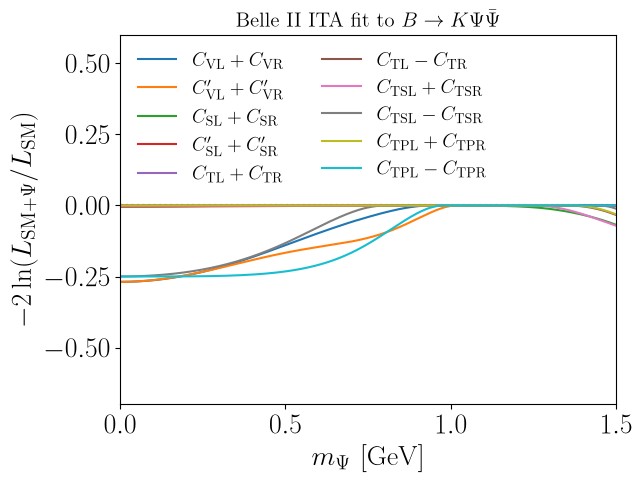

In [30]:
fig, axes = plt.subplots(nrows=1, ncols=1)

mX_vals = np.append(1e-10, np.linspace(1e-2, 1.5, 1000))

axes.plot([-1, 3], [-1, -1], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-4, -4], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-9, -9], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-16, -16], ls = '--', color='k',alpha = 0.1);
axes.plot([-1, 3], [-25, -25], ls = '--', color='k',alpha = 0.1);

axes.plot([-1, 3], [0, 0], ls = ':', color='k');
axes.plot([-1, 3], [mu_min, mu_min], ls = ':', color='k');
tot1, = axes.plot(mX_vals, LL_vals_FVV);
tot2, = axes.plot(mX_vals, LL_vals_FVA);
tot3, = axes.plot(mX_vals, LL_vals_FSS);
tot4, = axes.plot(mX_vals, LL_vals_FSP);
tot5, = axes.plot(mX_vals, LL_vals_FTT);
tot6, = axes.plot(mX_vals, LL_vals_FTtT);
tot7, = axes.plot(mX_vals, LL_vals_FTS);
tot8, = axes.plot(mX_vals, LL_vals_FTtS);
tot9, = axes.plot(mX_vals, LL_vals_FTP);
tot10, = axes.plot(mX_vals, LL_vals_FTtP);

axes.set_xlim(0,1.5)
axes.set_ylim(-0.7,0.6)
axes.set_xlabel(r'$m_\Psi \,\, [\mathrm{GeV}]$');
axes.set_ylabel(r'$-2\ln(L_{\mathrm{SM} + \Psi}/L_\mathrm{SM})$');

# axes.yaxis.set_label_coords(-0.12,0.5)

axes.legend([tot1,tot2,tot3,tot4,tot5,tot6,tot7,tot8,tot9,tot10], [
    r'$C_{\rm VL} + C_{\rm VR}$',
    r'$C_{\rm VL}^\prime + C_{\rm VR}^\prime$',
    r'$C_{\rm SL} + C_{\rm SR}$',
    r'$C_{\rm SL}^\prime + C_{\rm SR}^\prime$',
    r'$C_{\rm TL} + C_{\rm TR}$',
    r'$C_{\rm TL} - C_{\rm TR}$',
    r'$C_{\rm TSL} + C_{\rm TSR}$',
    r'$C_{\rm TSL} - C_{\rm TSR}$',
    r'$C_{\rm TPL} + C_{\rm TPR}$',
    r'$C_{\rm TPL} - C_{\rm TPR}$'
    ], loc='upper left',fontsize=14,frameon=False,ncol=2)

plt.title(r'Belle~II ITA fit to $B\to K \Psi \bar{\Psi}$', fontsize = 15);

fig.set_size_inches(6.4, 4.8)
plt.savefig(SAVE_DIR / "3body_spin32_mass.pdf", bbox_inches='tight')